# u01: S&P 500 + gold, a 50/50 portfolio

Does mixing the S&P 500 with gold lower risk? This notebook measures each asset's volatility and the correlation between them over five years of daily data. It then shows why a 50/50 portfolio is less volatile than the weighted average of its two parts, and how much that depends on the correlation.

- **Data:** daily closes from yfinance for `^GSPC` (the S&P 500 index) and `GLD` (SPDR Gold Shares, an ETF that holds gold), 2021-11-22 to 2026-11-21.
- **Convention:** asset 1 = S&P 500, asset 2 = gold. `w` is the weight in the S&P 500, and `1 − w` is the weight in gold.
- **Caveat:** `^GSPC` is a price index, so its returns exclude dividends. `GLD` is a fund, and its adjusted close is net of the fund's expense ratio.

In [1]:
# Setup: imports and parameters used throughout the notebook
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

SPX, GLD = "^GSPC", "GLD"                 # asset 1 = S&P 500, asset 2 = gold
TICKERS = [SPX, GLD]
START, END = "2021-11-22", "2026-11-21"   # fixed window -> reproducible
TRADING_DAYS = 252
W_5050 = 0.5                              # weight in the S&P 500 for the 50/50 portfolio

## 1. Data and daily returns

In [2]:
# Download with fixed dates for the past 5 years
prices = yf.download(TICKERS, start=START, end=END, auto_adjust=True, progress=False)["Close"]

empty = prices.columns[prices.isna().all()]
assert empty.empty, f"No data for: {list(empty)}"

# Step 1, daily return:
# rₜ = (Pₜ − Pₜ₋₁) / Pₜ₋₁
# [TICKERS] fixes the column order to S&P 500, gold
returns = prices.pct_change(fill_method=None).dropna()[TICKERS]
print(f"{len(returns)} daily returns, {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}")

1254 daily returns, 2021-11-23 to 2026-11-20


## 2. Volatility and correlation

In [3]:
# Volatility and correlation

# Step 2, mean daily return:
# r̄ = (1/N) · Σₜ rₜ
# Step 3, daily volatility (sample standard deviation, which is what returns.std() computes):
# σ_daily = √[ (1/(N−1)) · Σₜ (rₜ − r̄)² ]
daily_vol = returns.std()

# Step 4, annual volatility:
# σ_annual = σ_daily · √252
annual_vol = daily_vol * np.sqrt(TRADING_DAYS)  # sqrt-of-time scaling

# Step 5, correlation (Pearson):
# Cov(X,Y) = (1/(N−1)) · Σₜ (xₜ − x̄)(yₜ − ȳ)
# ρ = Cov(X,Y) / (σ_X · σ_Y) ρ ∈ [−1, 1]
# ρ: measured correlation
rho = returns.corr().loc[SPX, GLD]   # full matrix, then the one off-diagonal cell

# Named once here, used by every formula below
sigma_1 = annual_vol[SPX]   # σ₁: S&P 500 annual volatility
sigma_2 = annual_vol[GLD]   # σ₂: GLD annual volatility

print("Annual volatility:\n", annual_vol.round(4))
print("Correlation:", round(rho, 3))

Annual volatility:
 Ticker
^GSPC    0.1730
GLD      0.1933
dtype: float64
Correlation: 0.178


In [4]:
# Verification: compute by hand with numpy and compare to pandas
x = returns[SPX].to_numpy()   # S&P daily returns as a plain array
y = returns[GLD].to_numpy()   # gold daily returns
N = len(x)

# Step 2: r̄ = (1/N) · Σₜ rₜ
x_bar = np.sum(x) / N
y_bar = np.sum(y) / N

# Step 3: σ_daily = √[ (1/(N−1)) · Σₜ (rₜ − r̄)² ]
sigma_x = np.sqrt(np.sum((x - x_bar) ** 2) / (N - 1))
sigma_y = np.sqrt(np.sum((y - y_bar) ** 2) / (N - 1))

# Step 4: σ_annual = σ_daily · √252
sigma_x_annual = sigma_x * np.sqrt(TRADING_DAYS)
sigma_y_annual = sigma_y * np.sqrt(TRADING_DAYS)

# Step 5: Cov(X,Y) = (1/(N−1)) · Σₜ (xₜ − x̄)(yₜ − ȳ)
cov_xy = np.sum((x - x_bar) * (y - y_bar)) / (N - 1)

# ρ = Cov(X,Y) / (σ_X · σ_Y)
rho_np = cov_xy / (sigma_x * sigma_y)

# Compare with pandas (isclose allows tiny floating-point differences)
assert np.isclose(sigma_x, daily_vol[SPX])
assert np.isclose(sigma_y, daily_vol[GLD])
assert np.isclose(sigma_x_annual, sigma_1)
assert np.isclose(sigma_y_annual, sigma_2)
assert np.isclose(rho_np, rho)

print(f"√252 = {np.sqrt(TRADING_DAYS):.4f}")
print(f"σ_daily  S&P: {sigma_x:.6f}         (pandas {daily_vol[SPX]:.6f})")
print(f"σ_daily  GLD: {sigma_y:.6f}         (pandas {daily_vol[GLD]:.6f})")
print(f"σ_annual S&P: {sigma_x_annual:.4f}           (pandas {sigma_1:.4f})")
print(f"σ_annual GLD: {sigma_y_annual:.4f}           (pandas {sigma_2:.4f})")
print(f"ρ:            {rho_np:.6f}         (pandas {rho:.6f})")

√252 = 15.8745
σ_daily  S&P: 0.010899         (pandas 0.010899)
σ_daily  GLD: 0.012176         (pandas 0.012176)
σ_annual S&P: 0.1730           (pandas 0.1730)
σ_annual GLD: 0.1933           (pandas 0.1933)
ρ:            0.178030         (pandas 0.178030)


## 3. The 50/50 portfolio

In [5]:
# 50/50 portfolio

# Step 6, portfolio daily return (weighted sum, one value per day):
# r_p,t = w₁ · r₁,t + w₂ · r₂,t
# In matrix form: r_p = R · w   (R = returns matrix N×2, w = weights 2×1)
# In code, the vector w is `weights`; the scalar w (weight in asset 1) is W_5050, so w₁ = w, w₂ = 1 − w
weights = pd.Series({SPX: W_5050, GLD: 1 - W_5050})   # weights matched by ticker name, not position
port_returns = returns @ weights                        # @ = matrix multiplication → N daily values

# Step 7, portfolio volatility, measured directly from its own returns:
# σ_p = std(r_p) · √252
port_vol_measured = port_returns.std() * np.sqrt(TRADING_DAYS)

# Step 8, Markowitz two-asset variance formula (no portfolio returns needed):
# σ²_p = w₁²σ₁² + w₂²σ₂² + 2·w₁·w₂·ρ·σ₁·σ₂
# Same formula with w₁ = w, w₂ = 1 − w, written once as a function and reused in Steps 11 and 12
def portfolio_vol(w, sigma_1, sigma_2, rho):
    # σp² = w²σ₁² + (1 − w)²σ₂² + 2·w·(1 − w)·ρ·σ₁·σ₂
    var = w**2 * sigma_1**2 + (1 - w)**2 * sigma_2**2 + 2 * w * (1 - w) * rho * sigma_1 * sigma_2
    # σp = √σp²
    return np.sqrt(var)

port_vol_formula = portfolio_vol(W_5050, sigma_1, sigma_2, rho)

assert np.isclose(port_vol_measured, port_vol_formula)   # two routes, same answer

print(f"σ_annual S&P:      {sigma_1:.4f}")
print(f"σ_annual GLD:      {sigma_2:.4f}")
print(f"Simple average:    {(sigma_1 + sigma_2) / 2:.4f}")
print(f"50/50 (measured):  {port_vol_measured:.4f}")
print(f"50/50 (formula):   {port_vol_formula:.4f}")

σ_annual S&P:      0.1730
σ_annual GLD:      0.1933
Simple average:    0.1831
50/50 (measured):  0.1407
50/50 (formula):   0.1407


## 4. Is the correlation stable?

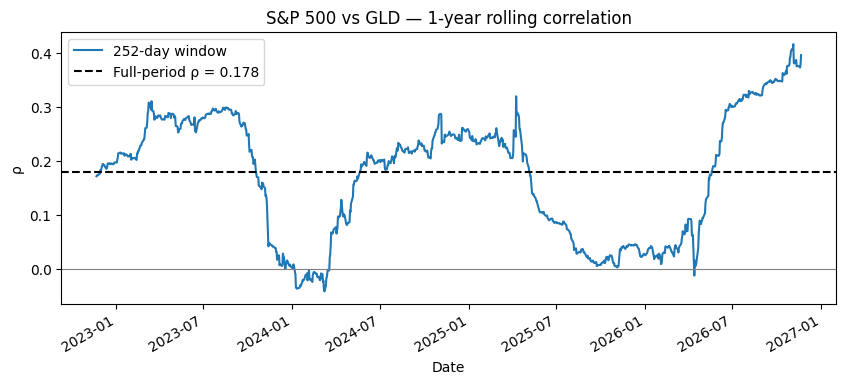

In [6]:
# Step 9, rolling correlation over a 252-day (one-year) window:
# ρₜ = Cov(X,Y) / (σ_X · σ_Y), computed only on days t−251 … t
WINDOW = 252
rolling_rho = returns[SPX].rolling(WINDOW).corr(returns[GLD])

ax = rolling_rho.plot(figsize=(10, 4), label=f"{WINDOW}-day window")
ax.axhline(rho, linestyle="--", color="black", label=f"Full-period ρ = {rho:.3f}")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("S&P 500 vs GLD — 1-year rolling correlation")
ax.set_ylabel("ρ")
ax.legend()
plt.show()

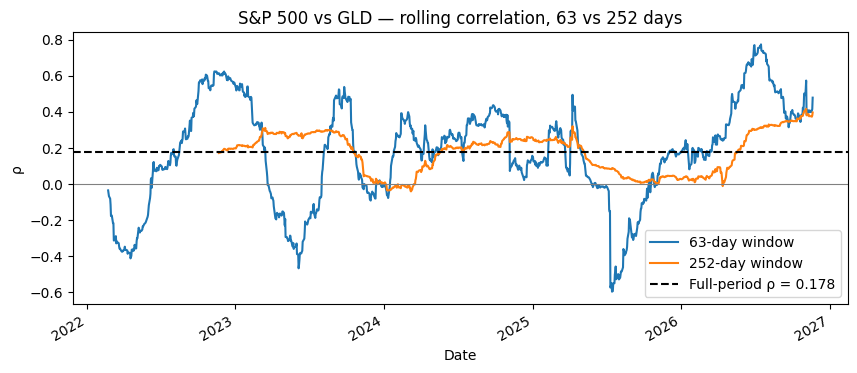

In [7]:
# Step 10, compare window lengths: 63 days (~3 months) vs 252 days (~1 year)
# Same formula as Step 9, ρₜ = Cov(X,Y) / (σ_X · σ_Y), on days t−(W−1) … t
# Shorter window → fewer points per estimate → noisier, but reacts faster
# Sampling error of ρ shrinks roughly as 1/√W
WINDOWS = [63, 252]

ax = None
for W in WINDOWS:
    rolling_rho_w = returns[SPX].rolling(W).corr(returns[GLD])
    ax = rolling_rho_w.plot(ax=ax, figsize=(10, 4), label=f"{W}-day window")

ax.axhline(rho, linestyle="--", color="black", label=f"Full-period ρ = {rho:.3f}")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("S&P 500 vs GLD — rolling correlation, 63 vs 252 days")
ax.set_ylabel("ρ")
ax.legend()
plt.show()

## 5. How much does correlation matter?

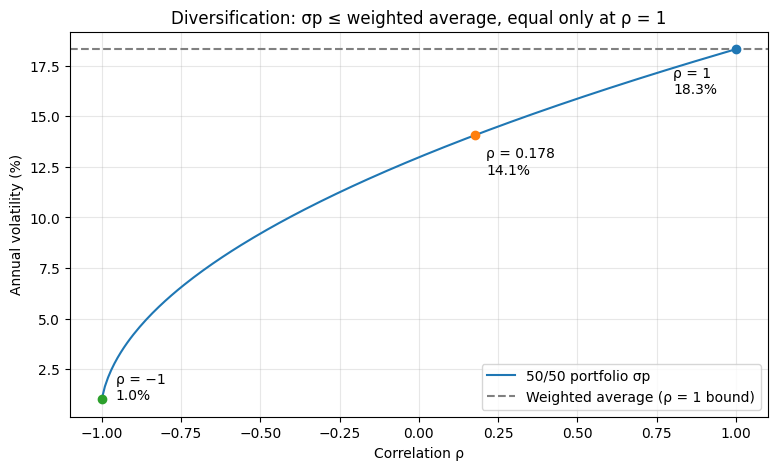

ρ = −1 zero-risk weight: 0.528 S&P / 0.472 gold


In [8]:
# Step 11, volatility vs correlation for the 50/50 portfolio
# Inputs, measured above in Steps 4–5 (annualised): σ₁ = sigma_1, σ₂ = sigma_2, ρ = rho
# portfolio_vol is the Step 8 formula
rhos = np.linspace(-1, 1, 201)
vols = portfolio_vol(W_5050, sigma_1, sigma_2, rhos)

# Upper bound (ρ = 1): σp = w·σ₁ + (1 − w)·σ₂   ← perfect square (a + b)²
avg_vol = W_5050 * sigma_1 + (1 - W_5050) * sigma_2

plt.figure(figsize=(9, 5))
plt.plot(rhos, vols * 100, label="50/50 portfolio σp")
plt.axhline(avg_vol * 100, ls="--", c="gray", label="Weighted average (ρ = 1 bound)")
# (ρ, label, text offset in points); offsets keep each label inside the axes
markers = [(1, "ρ = 1", (-45, -32)), (rho, f"ρ = {rho:.3f}", (8, -28)), (-1, "ρ = −1", (10, 0))]
for r, lbl, offset in markers:
    v = portfolio_vol(W_5050, sigma_1, sigma_2, r)
    plt.scatter(r, v * 100, zorder=3)
    plt.annotate(f"{lbl}\n{v*100:.1f}%", (r, v * 100), textcoords="offset points", xytext=offset)
plt.xlabel("Correlation ρ"); plt.ylabel("Annual volatility (%)")
plt.title("Diversification: σp ≤ weighted average, equal only at ρ = 1")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Zero-risk weight at ρ = −1:  w·σ₁ = (1 − w)·σ₂  →  w* = σ₂ / (σ₁ + σ₂)
w_star = sigma_2 / (sigma_1 + sigma_2)
print(f"ρ = −1 zero-risk weight: {w_star:.3f} S&P / {1 - w_star:.3f} gold")

In [9]:
# Step 12, interactive sliders for ρ and w
y_max = max(sigma_1, sigma_2) * 100 * 1.15   # y-axis headroom above the riskier asset

def explore(rho=rho, w=W_5050):
    ws = np.linspace(0, 1, 201)
    # Full curve σp(w) for the chosen ρ
    curve = portfolio_vol(ws, sigma_1, sigma_2, rho)
    vp = portfolio_vol(w, sigma_1, sigma_2, rho)
    plt.figure(figsize=(9, 5))
    plt.plot(ws, curve * 100, label=f"σp(w), ρ = {rho:.2f}")
    # Straight line = weighted average, the ρ = 1 case
    plt.plot(ws, (ws * sigma_1 + (1 - ws) * sigma_2) * 100, "--", c="gray", label="ρ = 1 line")
    plt.scatter(w, vp * 100, c="red", zorder=3, label=f"w = {w:.2f} → σp = {vp*100:.1f}%")
    plt.xlabel("Weight in S&P 500 (w)"); plt.ylabel("Annual volatility (%)")
    plt.ylim(0, y_max); plt.legend(); plt.grid(alpha=0.3); plt.show()

# The trailing ; hides interact's return value
interact(explore,
         rho=FloatSlider(min=-1, max=1, step=0.01, value=rho, description="ρ"),
         w=FloatSlider(min=0, max=1, step=0.01, value=W_5050, description="w (S&P)"));

interactive(children=(FloatSlider(value=0.17803029670493187, description='ρ', max=1.0, min=-1.0, step=0.01), F…